<a href="https://colab.research.google.com/github/chimmy003/COU07506_WEEK2_240242496495/blob/main/COU07506_Week01_240242496495.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# COU 07506 Digital Signal Processing — Week 01: Setting Up the DSP Laboratory
Name: chimilo chimilo laban  
Registration No.: 240242496495  
Class: BEng24COE-3  
Group: 02
Date: 20.11.2026

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile
plt.rcParams["figure.figsize"] = (9, 3.5)

In [ ]:
import sys
!{sys.executable} -m pip install -q soundfile

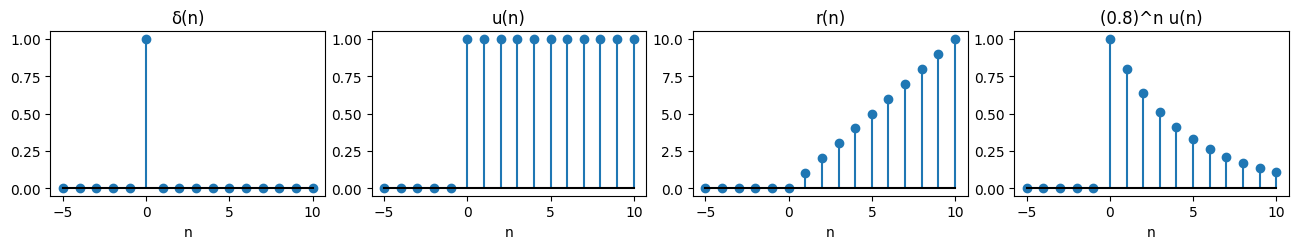

In [ ]:
n = np.arange(-5, 11)
delta = (n == 0).astype(float)
step  = (n >= 0).astype(float)
ramp  = n * step
expo  = 0.8**n * step

fig, axes = plt.subplots(1, 4, figsize=(13, 2.6))
for ax, x, title in zip(axes, [delta, step, ramp, expo],
                        ["δ(n)", "u(n)", "r(n)", "(0.8)^n u(n)"]):
    ax.stem(n, x, basefmt="k-")
    ax.set_title(title); ax.set_xlabel("n")
plt.tight_layout(); plt.show()

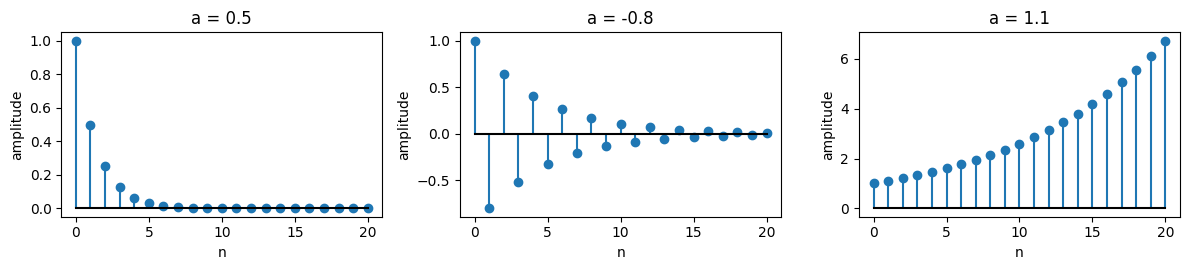

In [ ]:
n = np.arange(0, 21)
fig, axes = plt.subplots(1, 3, figsize=(12, 2.8))
for ax, a in zip(axes, [0.5, -0.8, 1.1]):
    ax.stem(n, a**n, basefmt="k-")
    ax.set_title(f"a = {a}")
    ax.set_xlabel("n"); ax.set_ylabel("amplitude")
plt.tight_layout(); plt.show()

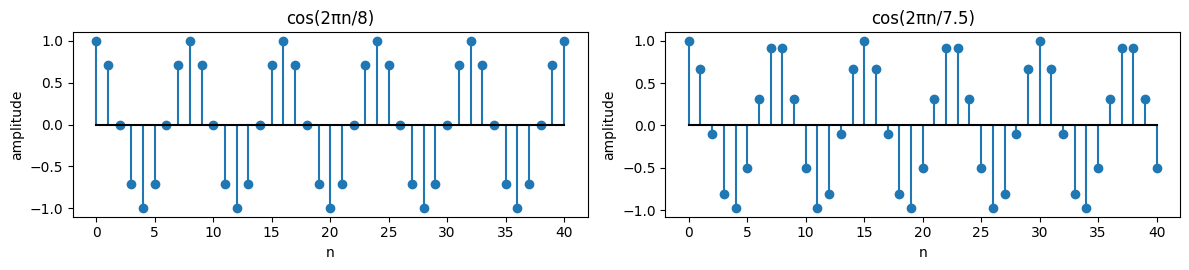

In [ ]:
n = np.arange(0, 41)
fig, axes = plt.subplots(1, 2, figsize=(12, 2.8))
axes[0].stem(n, np.cos(2*np.pi*n/8), basefmt="k-");   axes[0].set_title("cos(2πn/8)")
axes[1].stem(n, np.cos(2*np.pi*n/7.5), basefmt="k-"); axes[1].set_title("cos(2πn/7.5)")
for ax in axes:
    ax.set_xlabel("n"); ax.set_ylabel("amplitude")
plt.tight_layout(); plt.show()

fs = 16000 Hz, duration = 2.00 s, samples = 32000


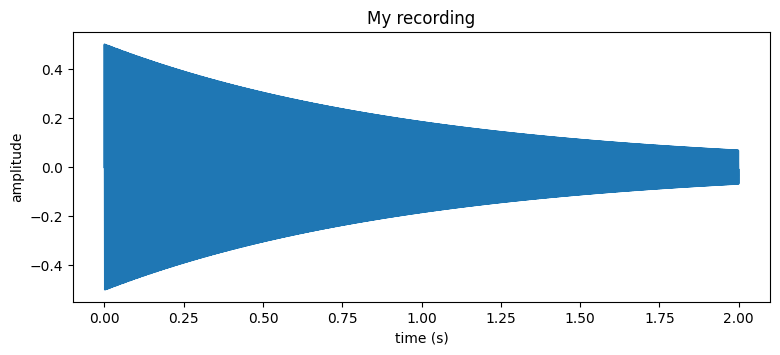

In [ ]:
import os
import soundfile as sf
fname = "my_voice.wav"

if os.path.exists(fname):
    try:
        # Read using soundfile which supports OggS containers
        x, fs = sf.read(fname)
        if x.ndim > 1:
            x = x.mean(axis=1)
        x = x / np.max(np.abs(x))
    except Exception as e:
        print(f"Failed to load audio: {e}")
        fs = 16000
        t = np.arange(0, 2, 1/fs)
        x = 0.5*np.sin(2*np.pi*440*t) * np.exp(-t)
else:
    fs = 16000
    t = np.arange(0, 2, 1/fs)
    x = 0.5*np.sin(2*np.pi*440*t) * np.exp(-t)

t = np.arange(len(x)) / fs
print(f"fs = {fs} Hz, duration = {len(x)/fs:.2f} s, samples = {len(x)}")
plt.plot(t, x); plt.xlabel("time (s)"); plt.ylabel("amplitude")
plt.title("My recording"); plt.show()

fs = 16000 Hz, duration = 2.00 s, samples = 32000


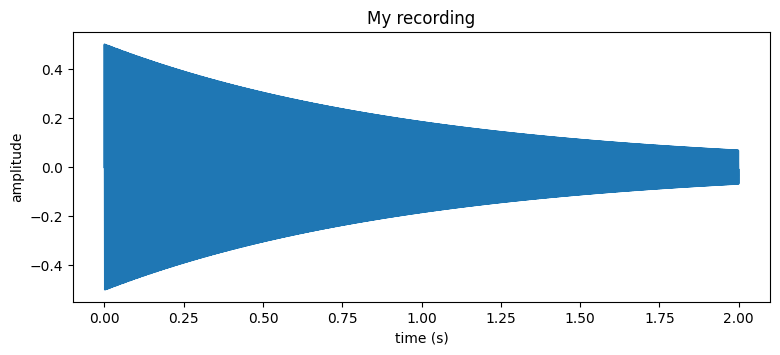

In [ ]:
import os
fname = "my_voice.wav"
if os.path.exists(fname):
    fs, x = wavfile.read(fname)
    if x.ndim > 1:
        x = x.mean(axis=1)
    x = x / np.max(np.abs(x))
else:
    fs = 16000
    t = np.arange(0, 2, 1/fs)
    x = 0.5*np.sin(2*np.pi*440*t) * np.exp(-t)

t = np.arange(len(x)) / fs
print(f"fs = {fs} Hz, duration = {len(x)/fs:.2f} s, samples = {len(x)}")
plt.plot(t, x); plt.xlabel("time (s)"); plt.ylabel("amplitude")
plt.title("My recording"); plt.show()

In [ ]:
from IPython.display import Audio
Audio(x, rate=fs)

1. sampling rate is 48,000 Hz
 One minute in mono: 48,000 samples/s x 60 s = 2,880,000 numbers.
2. this is because A discrete-time signal x(n) is defined only at integer values of n
3. ability (BIBO stability: bounded input, bounded output).
An LTI system is BIBO stable only if its impulse response is absolutely summable:
